# 07 · Extension – city comparison and next-day AQI forecast

**Requirement covered (topic slide, *Evaluation and extension*):** *"compare Delhi, Chandigarh, Mumbai or nearby cities; predict next-day AQI."*

The brief says *"or nearby cities"*, so besides the three named cities we add the neighbours that the data allows:

| City | Why it is included |
|---|---|
| **Delhi** | named; the most polluted metro |
| **Chandigarh** | named; only 10 months of data (Sep 2019 → Jul 2020) |
| **Mumbai** | named; coastal, western India (61 % of its AQI values are missing) |
| **Amritsar** | Punjab – Chandigarh's neighbour in the stubble-burning belt |
| **Gurugram** | Haryana – Delhi-NCR / Chandigarh's neighbour |
| **Lucknow, Jaipur** | rest of the northern belt (Lucknow: full 5.5 years) |
| **Bengaluru** | clean southern reference with full history |

**Part A** compares the cities (levels, pollutants, seasonality, festival/lockdown response, co-movement, how well the models work in each).
**Part B** forecasts **tomorrow's AQI** (regression) and **tomorrow's category** (classification) and tests whether ML beats the "tomorrow = today" persistence baseline.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import warnings; warnings.filterwarnings("ignore")
import json, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.dates as mdates, seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report

from src import db, config, features, modeling, evaluate, cpcb
from src.config import (LABELS, BUCKET_ORDER, COMPARE_CITIES, CORE_CITIES, TEST_START, LOCKDOWN_START, LOCKDOWN_END, FESTIVALS, aqi_to_bucket)
from src.viz import set_style, save_fig
set_style(); pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40)

conn = db.get_conn()
df = pd.read_sql_query("SELECT * FROM aqi_features", conn, parse_dates=["date"])
ok = df[df.is_suspect == 0].copy()
pop = df[df.in_model_pop == 1].copy()
CMP = COMPARE_CITIES
CITY_COLORS = {c: col for c, col in zip(CMP, ["#d62728", "#ff7f0e", "#1f77b4", "#2ca02c", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f"])}
lo, hi = ok[ok.city == "Chandigarh"].date.min(), ok[ok.city == "Chandigarh"].date.max()
print(f"like-for-like window = Chandigarh's data period: {lo:%d %b %Y} → {hi:%d %b %Y}")
print({c: int(ok[(ok.city == c) & ok.aqi.notna() & ok.date.between(lo, hi)].shape[0]) for c in CMP}, "← days with AQI in that window")

like-for-like window = Chandigarh's data period: 02 Sep 2019 → 01 Jul 2020
{'Delhi': 304, 'Chandigarh': 299, 'Mumbai': 304, 'Amritsar': 295, 'Gurugram': 304, 'Lucknow': 304, 'Jaipur': 304, 'Bengaluru': 304} ← days with AQI in that window


# Part A – City comparison

## A1 · Levels and composition (like-for-like window)
All numbers in this section use **only the days inside Chandigarh's window**, so every city is judged over the same months (Sep 2019 – Jun 2020, which includes Diwali 2019, winter smog, and the lockdown).

In [2]:
lw = ok[ok.city.isin(CMP) & ok.date.between(lo, hi)].copy()
lw["aqi_cpcb"], lw["dominant"] = cpcb.reconstruct_aqi(lw)
tab = lw.groupby("city").agg(days_with_aqi=("aqi", "count"), mean_aqi=("aqi", "mean"), median_aqi=("aqi", "median"), p90_aqi=("aqi", lambda s: s.quantile(.9)),
                             pct_poor_or_worse=("aqi", lambda s: (s.dropna() > 200).mean() * 100), pm25=("pm25", "mean"), pm10=("pm10", "mean"), no2=("no2", "mean"), co=("co", "mean"), o3=("o3", "mean"))
tab["main_driver"] = lw[lw.aqi.notna()].groupby("city")["dominant"].agg(lambda s: LABELS.get(s.mode().iloc[0], s.mode().iloc[0]) if s.notna().any() else "n/a")
tab = tab.loc[CMP].round(1); tab

,days_with_aqi,mean_aqi,median_aqi,p90_aqi,pct_poor_or_worse,pm25,pm10,no2,co,o3,main_driver
city,,,,,,,,,,,
Delhi,304,216.3,174.0,380.1,44.7,106.0,190.6,38.9,1.2,38.2,PM10
Chandigarh,299,96.5,82.0,171.8,7.7,41.0,85.7,11.7,0.6,20.0,PM10
Mumbai,304,109.6,88.5,192.0,8.2,41.2,95.4,25.5,0.7,25.2,PM10
Amritsar,295,112.5,91.0,202.2,10.2,48.7,99.4,13.0,0.7,28.0,PM10
Gurugram,304,186.0,153.0,338.5,31.9,88.1,162.3,26.2,1.2,44.4,PM2.5
Lucknow,304,185.1,157.5,343.7,38.8,92.2,NaN,34.0,1.2,31.8,PM2.5
Jaipur,304,114.0,108.0,161.4,3.0,46.1,105.2,33.5,0.8,50.7,PM10
Bengaluru,304,81.1,78.0,103.7,0.0,30.9,66.1,23.7,0.9,34.2,PM10


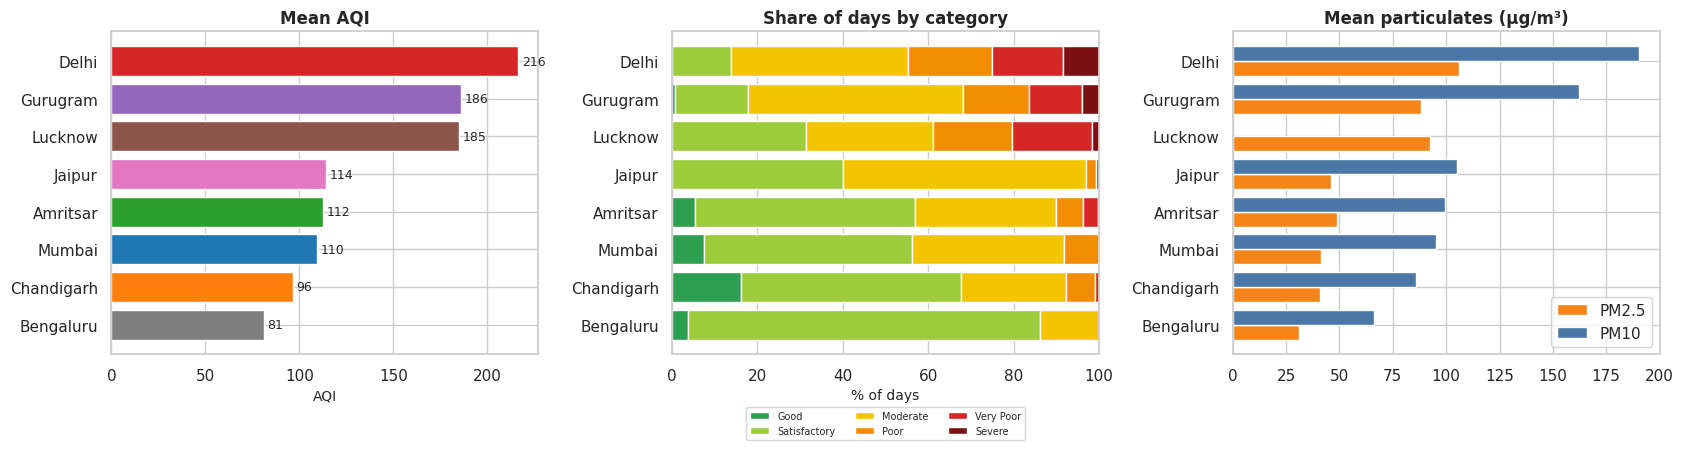

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
t = tab.sort_values("mean_aqi")
axes[0].barh(t.index, t.mean_aqi, color=[CITY_COLORS[c] for c in t.index]); axes[0].set_title("Mean AQI"); axes[0].set_xlabel("AQI")
for i, v in enumerate(t.mean_aqi): axes[0].text(v + 2, i, f"{v:.0f}", va="center", fontsize=9)
ct = pd.crosstab(lw[lw.aqi.notna()].city, lw[lw.aqi.notna()].aqi_bucket, normalize="index").reindex(columns=BUCKET_ORDER, fill_value=0).mul(100).loc[t.index]
left = np.zeros(len(ct))
for b in BUCKET_ORDER: axes[1].barh(ct.index, ct[b], left=left, color=config.BUCKET_COLORS[b], label=b); left += ct[b].values
axes[1].set_title("Share of days by category"); axes[1].legend(ncol=3, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.28)); axes[1].set_xlabel("% of days")
pm = tab.loc[t.index, ["pm25", "pm10"]]; y = np.arange(len(pm))
axes[2].barh(y - 0.2, pm.pm25, 0.4, label="PM2.5", color="#f58518"); axes[2].barh(y + 0.2, pm.pm10, 0.4, label="PM10", color="#4c78a8"); axes[2].set_yticks(y); axes[2].set_yticklabels(pm.index); axes[2].legend(); axes[2].set_title("Mean particulates (µg/m³)")
plt.tight_layout(); save_fig("07_city_levels"); plt.show()

### A2 · Month by month

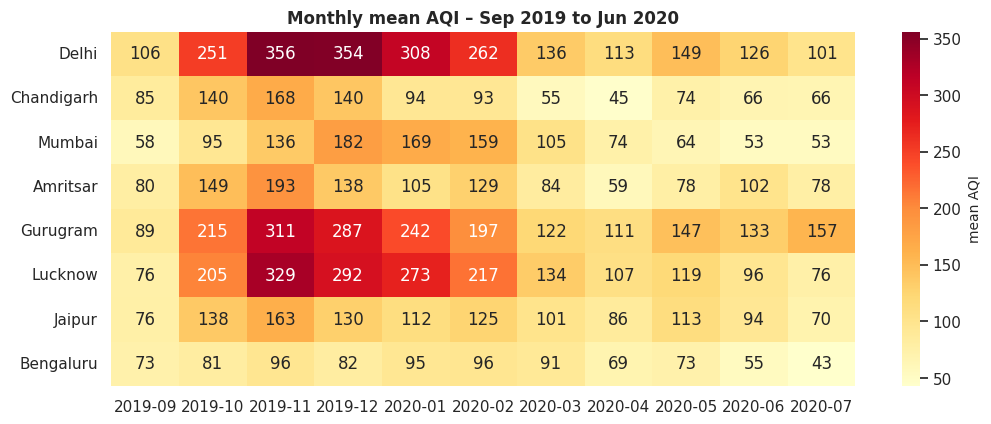

In [4]:
lw["ym"] = lw.date.dt.to_period("M").astype(str)
mon = lw.pivot_table(index="city", columns="ym", values="aqi", aggfunc="mean").loc[CMP]
fig, ax = plt.subplots(figsize=(12, 4.6)); sns.heatmap(mon, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "mean AQI"}); ax.set_title("Monthly mean AQI – Sep 2019 to Jun 2020"); ax.set_xlabel(""); ax.set_ylabel("")
save_fig("07_city_monthly"); plt.show()

### A3 · Do nearby cities move together? Correlation and lead/lag
Daily AQI series are correlated across the window; the cross-correlation at different lags shows whether pollution episodes appear in one city *before* another.

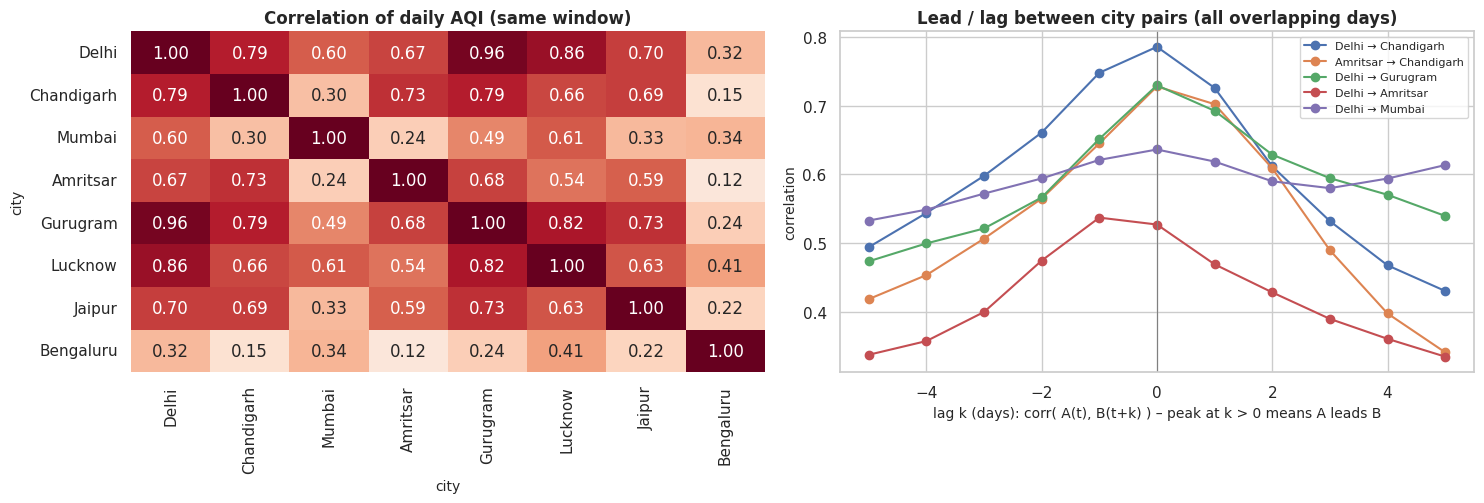

lag with the highest correlation: {'Delhi → Chandigarh': 0, 'Amritsar → Chandigarh': 0, 'Delhi → Gurugram': 0, 'Delhi → Amritsar': -1, 'Delhi → Mumbai': 0}


city,Delhi,Chandigarh,Mumbai,Amritsar,Gurugram,Lucknow,Jaipur,Bengaluru
city,,,,,,,,
Delhi,1.00,0.79,0.60,0.67,0.96,0.86,0.70,0.32
Chandigarh,0.79,1.00,0.30,0.73,0.79,0.66,0.69,0.15
Mumbai,0.60,0.30,1.00,0.24,0.49,0.61,0.33,0.34
Amritsar,0.67,0.73,0.24,1.00,0.68,0.54,0.59,0.12
Gurugram,0.96,0.79,0.49,0.68,1.00,0.82,0.73,0.24
Lucknow,0.86,0.66,0.61,0.54,0.82,1.00,0.63,0.41
Jaipur,0.70,0.69,0.33,0.59,0.73,0.63,1.00,0.22
Bengaluru,0.32,0.15,0.34,0.12,0.24,0.41,0.22,1.00


In [5]:
wide = lw.pivot_table(index="date", columns="city", values="aqi")[CMP]
corr = wide.corr(min_periods=100)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0, ax=axes[0], cbar=False); axes[0].set_title("Correlation of daily AQI (same window)")
full_w = ok[ok.city.isin(CMP)].pivot_table(index="date", columns="city", values="aqi")
pairs = [("Delhi", "Chandigarh"), ("Amritsar", "Chandigarh"), ("Delhi", "Gurugram"), ("Delhi", "Amritsar"), ("Delhi", "Mumbai")]
lags = range(-5, 6); xc = {}
for a, b in pairs:
    xc[f"{a} → {b}"] = [full_w[a].corr(full_w[b].shift(-k)) for k in lags]
xc = pd.DataFrame(xc, index=list(lags))
for c in xc: axes[1].plot(xc.index, xc[c], marker="o", label=c)
axes[1].axvline(0, color="grey", lw=0.8); axes[1].set_xlabel("lag k (days): corr( A(t), B(t+k) ) – peak at k > 0 means A leads B"); axes[1].set_ylabel("correlation"); axes[1].legend(fontsize=8); axes[1].set_title("Lead / lag between city pairs (all overlapping days)")
plt.tight_layout(); save_fig("07_city_correlation"); plt.show()
print("lag with the highest correlation:", {c: int(xc[c].idxmax()) for c in xc}); corr.round(2)

### A4 · Response to events – Diwali 2019 and the lockdown

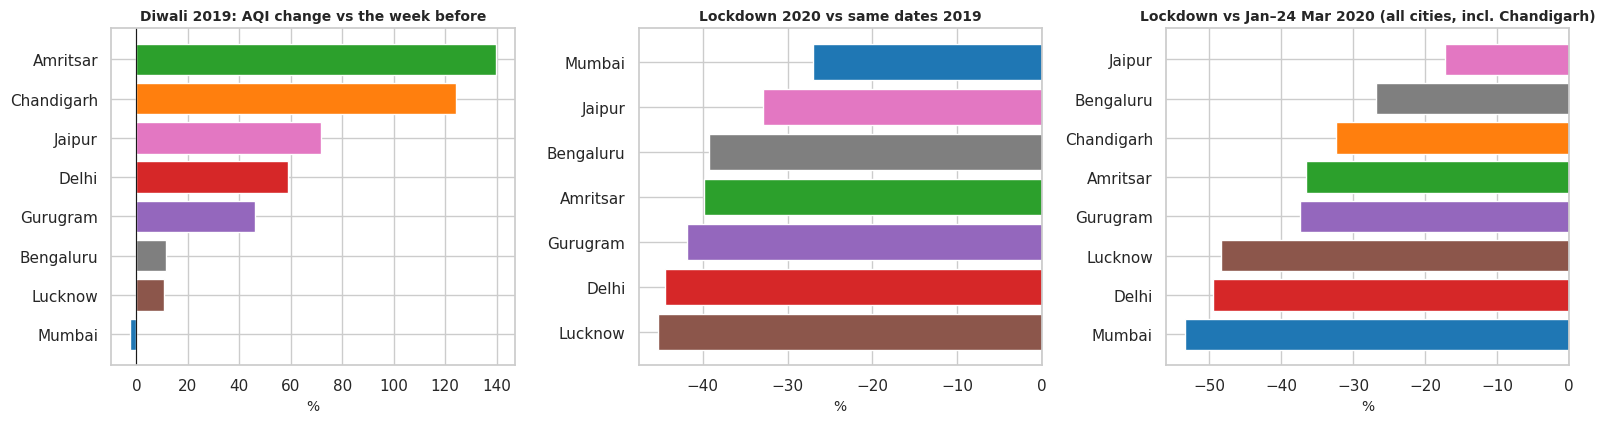

,Diwali 2019: baseline AQI,Diwali window AQI,Diwali % change,lockdown 2020 AQI,same dates 2019,lockdown vs 2019 %,Jan-24Mar 2020 AQI,lockdown vs pre-lockdown %
city,,,,,,,,
Delhi,246.0,391.4,59.1,125.4,225.5,-44.4,248.1,-49.5
Chandigarh,121.0,271.4,124.3,57.2,NaN,NaN,84.5,-32.3
Mumbai,97.7,95.2,-2.6,69.8,95.6,-27.0,149.5,-53.3
Amritsar,116.9,280.2,139.8,68.8,114.6,-39.9,108.5,-36.5
Gurugram,236.0,344.6,46.0,123.3,212.4,-41.9,196.5,-37.3
Lucknow,255.3,283.0,10.9,111.9,204.6,-45.3,216.4,-48.3
Jaipur,137.7,236.4,71.7,96.5,143.8,-32.9,116.5,-17.2
Bengaluru,67.9,75.8,11.7,70.6,116.2,-39.3,96.3,-26.8


In [6]:
def window_mean(city, a, b):
    g = ok[(ok.city == city) & ok.aqi.notna() & ok.date.between(a, b)]["aqi"]; return g.mean() if len(g) >= 3 else np.nan
d0 = pd.Timestamp(FESTIVALS["Diwali"][4])        # Diwali 2019
rows = []
for c in CMP:
    base = window_mean(c, d0 - pd.Timedelta(days=10), d0 - pd.Timedelta(days=4)); win = window_mean(c, d0 - pd.Timedelta(days=1), d0 + pd.Timedelta(days=3))
    pre20 = window_mean(c, "2020-01-01", "2020-03-24"); lk20 = window_mean(c, LOCKDOWN_START, LOCKDOWN_END); lk19 = window_mean(c, "2019-03-25", "2019-05-31")
    rows.append({"city": c, "Diwali 2019: baseline AQI": base, "Diwali window AQI": win, "Diwali % change": (win / base - 1) * 100,
                 "lockdown 2020 AQI": lk20, "same dates 2019": lk19, "lockdown vs 2019 %": (lk20 / lk19 - 1) * 100, "Jan-24Mar 2020 AQI": pre20, "lockdown vs pre-lockdown %": (lk20 / pre20 - 1) * 100})
ev = pd.DataFrame(rows).set_index("city").round(1)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, col, ttl in zip(axes, ["Diwali % change", "lockdown vs 2019 %", "lockdown vs pre-lockdown %"], ["Diwali 2019: AQI change vs the week before", "Lockdown 2020 vs same dates 2019", "Lockdown vs Jan–24 Mar 2020 (all cities, incl. Chandigarh)"]):
    v = ev[col].dropna().sort_values(); ax.barh(v.index, v.values, color=[CITY_COLORS[c] for c in v.index]); ax.set_title(ttl, fontsize=10); ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("%")
plt.tight_layout(); save_fig("07_city_events"); plt.show(); ev

The second panel excludes Chandigarh (no 2019 data); the third panel compares the lockdown with the weeks just before it – available for all cities but mixed with the normal winter→summer decline, so it overstates the lockdown effect. Both are shown for transparency.

### A5 · Model quality per city, and "local vs pooled" models
**Pooled model** = trained on all cities; **local model** = trained on one city only. Cut-off 1 Feb 2020 for everyone; test = 1 Feb – 1 Jul 2020 (includes the lockdown). Chandigarh has only ~140 training days, so this shows when a city-specific model is viable. *Zero-shot* = pooled model trained **without** Chandigarh.

In [7]:
sel = json.load(open(config.RESULTS_DIR / "selected_features.json")); NUM, CAT = sel["numeric"], sel["categorical"]; FEATS = NUM + CAT
bp = json.load(open(config.RESULTS_DIR / "regression_best_params.json"))["best_params"]
cat_r = modeling.regression_catalog()
def mk(name): 
    spec = cat_r[name]; est = clone(spec["est"]).set_params(**bp.get(name, {}));  return modeling.make_pipeline(est, NUM, CAT, spec["kind"])
CUT = pd.Timestamp("2020-02-01")
rows = []
for city in CORE_CITIES + ["Amritsar", "Gurugram"]:
    te = pop[(pop.city == city) & (pop.date >= CUT)]; trl = pop[(pop.city == city) & (pop.date < CUT)]
    for name in ["Linear Regression", "Gradient Boosting (HistGB)"]:
        approaches = {"pooled (all cities)": pop[pop.date < CUT], "local (this city only)": trl}
        if city == "Chandigarh": approaches["pooled, zero-shot (without Chandigarh)"] = pop[(pop.date < CUT) & (pop.city != "Chandigarh")]
        for ap, trd in approaches.items():
            if len(trd) < 30 or len(te) < 20: continue
            m = evaluate.regression_metrics(te.aqi, mk(name).fit(trd[FEATS], trd.aqi).predict(te[FEATS]))
            rows.append({"city": city, "model": name, "approach": ap, "n_train": len(trd), "n_test": len(te), "MAE": m["MAE"], "R2": m["R2"]})
lp = pd.DataFrame(rows).round(2)
piv = lp.pivot_table(index=["city", "model"], columns="approach", values="MAE"); piv

approach                               local (this city only)  pooled (all cities)  pooled, zero-shot (without Chandigarh)
city       model                                                                                                          
Amritsar   Gradient Boosting (HistGB)                   18.05                14.22                                     NaN
           Linear Regression                            16.84                21.10                                     NaN
Chandigarh Gradient Boosting (HistGB)                   14.49                 9.12                                    8.95
           Linear Regression                            15.13                13.69                                   13.78
Delhi      Gradient Boosting (HistGB)                   24.00                14.10                                     NaN
           Linear Regression                            32.22                15.37                                     NaN
Gurugram   Gradient Boosting (HistGB)                   15.90                14.15                                     NaN
           Linear Regression                            25.53                16.26                                     NaN
Mumbai     Gradient Boosting (HistGB)                    8.28                 8.48                                     NaN
           Linear Regression                             8.72                 8.42                                     NaN

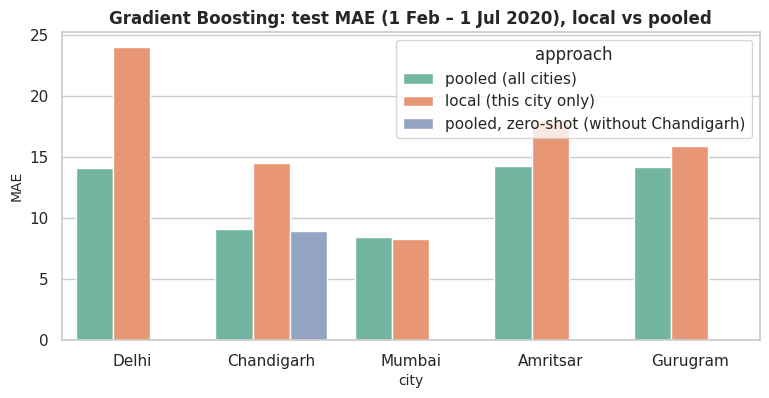

,city,model,approach,n_train,n_test,MAE,R2
4,Chandigarh,Linear Regression,pooled (all cities),19935,151,13.69,0.56
5,Chandigarh,Linear Regression,local (this city only),148,151,15.13,0.35
6,Chandigarh,Linear Regression,"pooled, zero-shot (without Chandigarh)",19787,151,13.78,0.55
7,Chandigarh,Gradient Boosting (HistGB),pooled (all cities),19935,151,9.12,0.78
8,Chandigarh,Gradient Boosting (HistGB),local (this city only),148,151,14.49,0.39
9,Chandigarh,Gradient Boosting (HistGB),"pooled, zero-shot (without Chandigarh)",19787,151,8.95,0.78


In [8]:
g = lp[lp.model == "Gradient Boosting (HistGB)"]
fig, ax = plt.subplots(figsize=(9, 4)); sns.barplot(data=g, x="city", y="MAE", hue="approach", ax=ax, palette="Set2"); ax.set_title("Gradient Boosting: test MAE (1 Feb – 1 Jul 2020), local vs pooled")
save_fig("07_local_vs_pooled"); plt.show(); lp[lp.city == "Chandigarh"]

# Part B – Forecasting tomorrow

We now predict **tomorrow's AQI** for every city from information available **today**. Rules to avoid cheating:
* only data up to the end of *today* is used for the lags and rolling statistics;
* *tomorrow's* calendar / festival flags may be used – festivals are known in advance;
* rows whose target date falls in the test period are removed from training (last training row = 30 Dec 2018);
* baseline = **persistence** ("tomorrow = today"), the standard bar that any forecast must clear.

## B1 · Build the forecasting table

In [9]:
nd = pop[pop.valid_next_day == 1].sort_values(["date", "city"]).reset_index(drop=True).copy()
tm = nd[["date"]].copy(); tm["date"] = tm["date"] + pd.Timedelta(days=1)                # features of the TARGET day
tm = features.add_event_features(features.add_calendar_features(tm))
TM_NUM = ["month_sin", "month_cos", "dayofweek", "is_weekend", "is_winter", "is_diwali_window", "is_holi_window", "is_dussehra_window", "is_stubble_season", "is_lockdown"]
for c in TM_NUM: nd["tm_" + c] = tm[c].values
nd["tm_season"] = tm["season"].values
G_AR   = ["aqi", "aqi_lag1", "aqi_lag2", "aqi_lag3", "aqi_lag7", "aqi_roll3", "aqi_roll7", "aqi_roll7_std", "aqi_change_1d"]
G_POLL = features.MODEL_POLLUTANTS + ["pm25_lag1", "pm10_lag1"]
G_TM   = ["tm_" + c for c in TM_NUM]
CAT_ND = ["tm_season", "city"]
train_nd = nd[nd.date <= "2018-12-30"].sort_values("date").reset_index(drop=True)          # target date <= 2018-12-31
test_nd = nd[nd.date >= TEST_START].reset_index(drop=True)
lock = pd.Timestamp(LOCKDOWN_START)
print(f"forecasting rows: train {len(train_nd):,} (2015-01 → 2018-12-30) | test {len(test_nd):,} (2019-01-01 → 2020-06-30)")
persist_mae = (test_nd.aqi_next - test_nd.aqi).abs().mean()
print("persistence baseline on test: ", {k: round(v, 3) for k, v in evaluate.regression_metrics(test_nd.aqi_next, test_nd.aqi).items()})

forecasting rows: train 12,235 (2015-01 → 2018-12-30) | test 10,779 (2019-01-01 → 2020-06-30)
persistence baseline on test:  {'MAE': 21.255, 'RMSE': 37.225, 'R2': 0.802}


## B2 · Which information helps? Feature-group ablation
Fixed, moderate hyper-parameters; three models; groups are added one by one. This answers: *do pollutants, tomorrow's calendar, and festival flags add anything beyond the AQI history?*

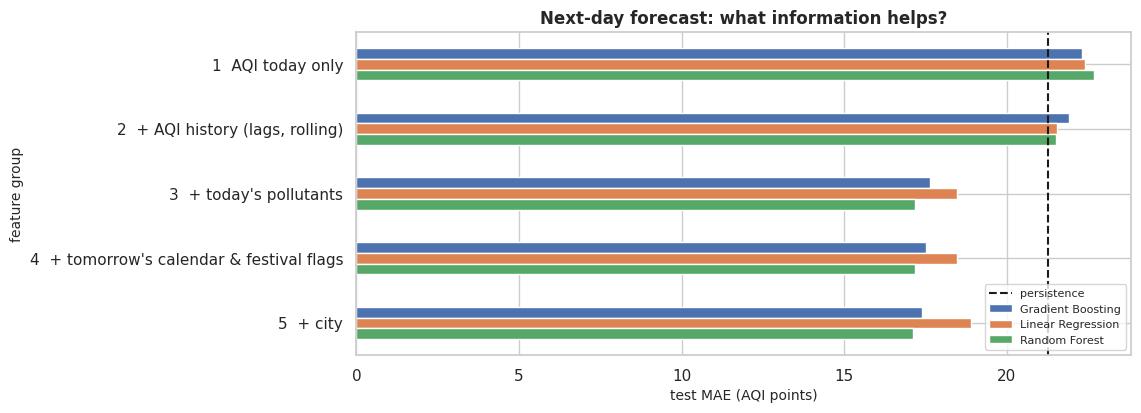

,feature group,model,MAE,RMSE,R2
0,PERSISTENCE (tomorrow = today),-,21.255,37.225,0.802
1,1 AQI today only,Linear Regression,22.407,36.503,0.810
2,1 AQI today only,Random Forest,22.693,36.569,0.809
3,1 AQI today only,Gradient Boosting,22.310,35.741,0.818
4,"2 + AQI history (lags, rolling)",Linear Regression,21.544,35.015,0.825
5,"2 + AQI history (lags, rolling)",Random Forest,21.516,34.793,0.827
6,"2 + AQI history (lags, rolling)",Gradient Boosting,21.911,34.645,0.829
7,3 + today's pollutants,Linear Regression,18.476,29.785,0.873
8,3 + today's pollutants,Random Forest,17.175,28.337,0.885
9,3 + today's pollutants,Gradient Boosting,17.641,28.312,0.886


In [10]:
def split_nd(feats): return [f for f in feats if f not in CAT_ND], [f for f in feats if f in CAT_ND]
def make_est(name):
    from sklearn.linear_model import LinearRegression
    from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
    return {"Linear Regression": (LinearRegression(), "linear"),
            "Random Forest": (RandomForestRegressor(n_estimators=100, min_samples_leaf=3, max_features=0.5, max_samples=0.7, n_jobs=-1, random_state=42), "tree"),
            "Gradient Boosting": (HistGradientBoostingRegressor(max_iter=200, learning_rate=0.06, max_leaf_nodes=15, l2_regularization=1.0, random_state=42), "tree")}[name]
def fit_nd(feats, name, tr=train_nd, te=test_nd):
    num, cat = split_nd(feats); est, kind = make_est(name)
    p = modeling.make_pipeline(est, num, cat, kind).fit(tr[num + cat], tr["aqi_next"]); return p, evaluate.regression_metrics(te["aqi_next"], p.predict(te[num + cat]))
groups = {"1  AQI today only": ["aqi"], "2  + AQI history (lags, rolling)": G_AR, "3  + today's pollutants": G_AR + G_POLL,
          "4  + tomorrow's calendar & festival flags": G_AR + G_POLL + G_TM, "5  + city": G_AR + G_POLL + G_TM + ["city"]}
rows = [{"feature group": "PERSISTENCE (tomorrow = today)", "model": "-", **{k: v for k, v in evaluate.regression_metrics(test_nd.aqi_next, test_nd.aqi).items()}}]
for gname, feats in groups.items():
    for name in ["Linear Regression", "Random Forest", "Gradient Boosting"]:
        _, m = fit_nd(feats, name); rows.append({"feature group": gname, "model": name, **m})
abl = pd.DataFrame(rows).round(3)
piv = abl[abl.model != "-"].pivot(index="feature group", columns="model", values="MAE"); piv.loc["PERSISTENCE (tomorrow = today)"] = persist_mae
fig, ax = plt.subplots(figsize=(10, 4.2)); piv.drop(index="PERSISTENCE (tomorrow = today)").plot.barh(ax=ax); ax.axvline(persist_mae, color="k", ls="--", label="persistence"); ax.invert_yaxis(); ax.legend(fontsize=8); ax.set_xlabel("test MAE (AQI points)")
ax.set_title("Next-day forecast: what information helps?"); save_fig("07_nextday_ablation"); plt.show(); abl

## B3 · Next-day AQI regression – all models, tuned (time-series CV on the training period)

In [11]:
ALL_ND = G_AR + G_POLL + G_TM + ["city"]; num_nd, cat_nd = split_nd(ALL_ND)
cat_rg = modeling.regression_catalog(); cat_rg.pop("XGBoost", None)
fitted, info = {}, {}
for name, spec in cat_rg.items():
    pipe, i = modeling.fit_model(name, spec, num_nd, cat_nd, train_nd[ALL_ND], train_nd["aqi_next"], scoring="neg_mean_absolute_error", n_iter=5)
    if not np.isfinite(i["cv_score"]): i["cv_score"] = cross_val_score(clone(pipe), train_nd[ALL_ND], train_nd["aqi_next"], cv=TimeSeriesSplit(3), scoring="neg_mean_absolute_error").mean()
    fitted[name], info[name] = pipe, i

  Mean (dummy)                 fitted in    0.0s   best params: -
  Linear Regression            fitted in    0.1s   best params: -
  Decision Tree                fitted in    2.0s   best params: {'min_samples_leaf': 20, 'max_depth': 6}
  Random Forest                fitted in   81.8s   best params: {'min_samples_leaf': 3, 'max_features': 0.5, 'max_depth': 20}
  Gradient Boosting (HistGB)   fitted in   23.4s   best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 31, 'learning_rate': 0.05, 'l2_regularization': 1.0}
  Neural Net (MLP)             fitted in    1.5s   best params: -


In [12]:
def sets_nd():
    return [("train", train_nd), ("test", test_nd), ("test_pre_lockdown", test_nd[test_nd.date + pd.Timedelta(days=1) < lock]), ("test_lockdown", test_nd[test_nd.date + pd.Timedelta(days=1) >= lock])]
res, log_rows = {}, []
res["Persistence (tomorrow = today)"] = {l: evaluate.regression_metrics(d.aqi_next, d.aqi) for l, d in sets_nd()}
for n, p in fitted.items(): res[n] = {l: evaluate.regression_metrics(d.aqi_next, p.predict(d[ALL_ND])) for l, d in sets_nd()}
for n, r in res.items():
    for es, m in r.items(): log_rows += evaluate.to_rows(n, "all", es, m)
pm = res["Persistence (tomorrow = today)"]["test"]["MAE"]
nd_tab = pd.DataFrame({n: {"CV MAE (train)": -info[n]["cv_score"] if n in info else np.nan, "test MAE": r["test"]["MAE"], "test RMSE": r["test"]["RMSE"], "test R2": r["test"]["R2"],
                           "skill vs persistence (1 − MAE/MAE_p)": 1 - r["test"]["MAE"] / pm, "MAE pre-lockdown": r["test_pre_lockdown"]["MAE"], "MAE lockdown": r["test_lockdown"]["MAE"]} for n, r in res.items()}).T
nd_tab = nd_tab.sort_values("test MAE").round(3); nd_tab

,CV MAE (train),test MAE,test RMSE,test R2,skill vs persistence (1 − MAE/MAE_p),MAE pre-lockdown,MAE lockdown
Random Forest,24.454,17.115,28.153,0.887,0.195,18.691,11.302
Gradient Boosting (HistGB),25.372,17.290,27.836,0.889,0.187,18.662,12.228
Linear Regression,25.501,18.905,29.876,0.873,0.111,20.696,12.297
Decision Tree,27.032,19.297,30.217,0.870,0.092,20.831,13.634
Persistence (tomorrow = today),NaN,21.255,37.225,0.802,0.000,23.838,11.725
Neural Net (MLP),28.526,21.724,32.350,0.851,-0.022,23.117,16.579
Mean (dummy),95.555,82.964,95.141,-0.291,-2.903,80.694,91.341


best forecasting model by time-series CV: Random Forest


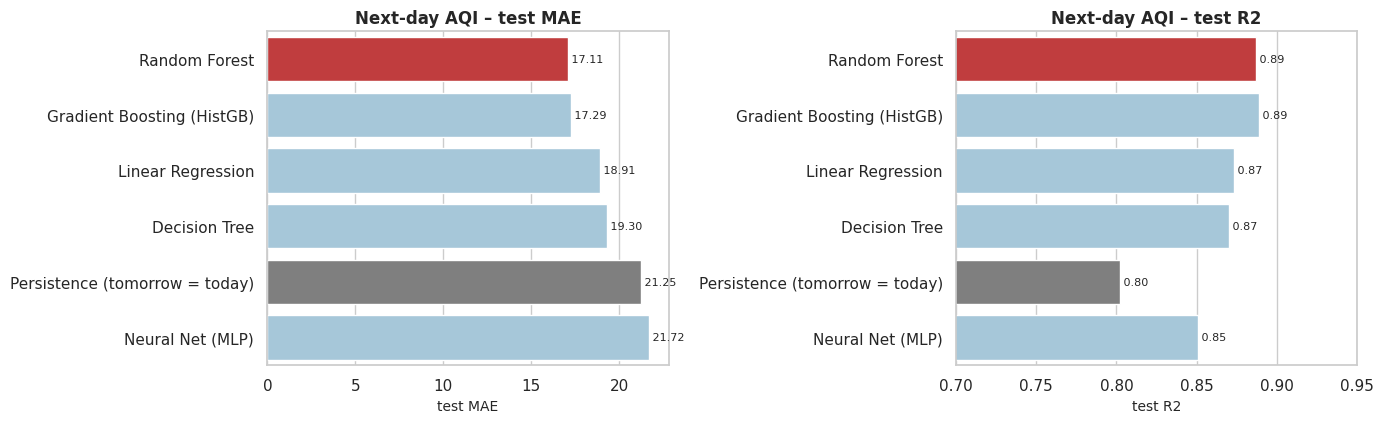

In [13]:
best_name = max((n for n in info if n != "Mean (dummy)"), key=lambda n: info[n]["cv_score"]); best = fitted[best_name]
print("best forecasting model by time-series CV:", best_name)
order = [n for n in nd_tab.index if n != "Mean (dummy)"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for ax, col in zip(axes, ["test MAE", "test R2"]):
    sns.barplot(x=nd_tab.loc[order, col], y=order, order=order, ax=ax, palette=["#d62728" if n == best_name else ("#7f7f7f" if "Persistence" in n else "#9ecae1") for n in order]); ax.set_ylabel(""); ax.set_title(f"Next-day AQI – {col}")
    for i, n in enumerate(order): ax.text(nd_tab.loc[n, col], i, f" {nd_tab.loc[n, col]:.2f}", va="center", fontsize=8)
axes[1].set_xlim(0.7, 0.95); plt.tight_layout(); save_fig("07_nextday_model_comparison"); plt.show()

### B3.1 Where does the forecast help? – by city, by AQI level, around Diwali

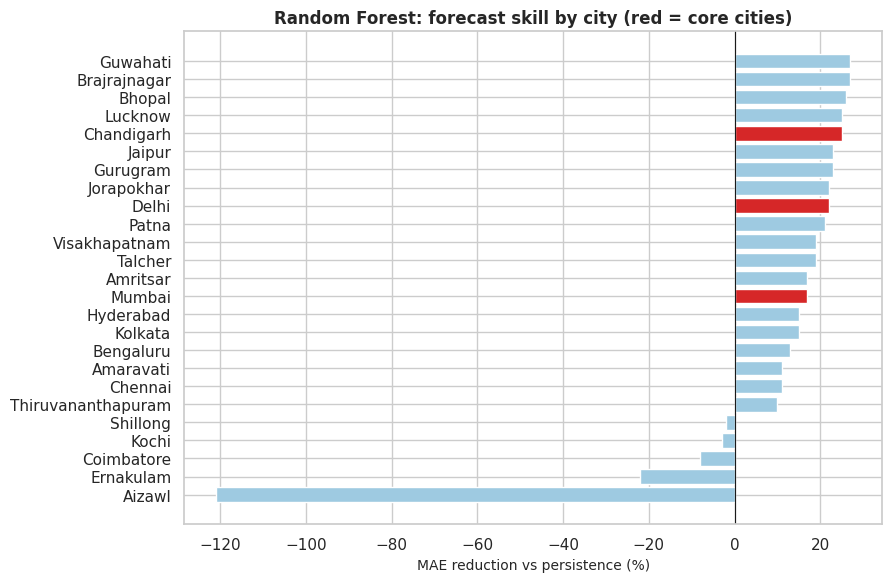

,n,mean_aqi,MAE_model,MAE_persistence,skill
city,,,,,
Guwahati,490,140.29,28.59,39.28,0.27
Brajrajnagar,403,145.68,19.15,26.13,0.27
Bhopal,276,133.10,16.15,21.89,0.26
Lucknow,547,186.98,24.83,33.30,0.25
Chandigarh,294,96.82,14.52,19.40,0.25
Jaipur,547,115.08,14.24,18.54,0.23
Gurugram,545,182.51,26.68,34.66,0.23
Jorapokhar,452,153.79,22.08,28.30,0.22
Delhi,547,214.79,27.71,35.51,0.22


In [14]:
tp = test_nd.assign(pred=best.predict(test_nd[ALL_ND])); tp["abs_err"] = (tp.pred - tp.aqi_next).abs(); tp["abs_err_persist"] = (tp.aqi - tp.aqi_next).abs()
city_nd = tp.groupby("city").agg(n=("aqi", "size"), mean_aqi=("aqi_next", "mean"), MAE_model=("abs_err", "mean"), MAE_persistence=("abs_err_persist", "mean")); city_nd["skill"] = 1 - city_nd.MAE_model / city_nd.MAE_persistence
city_nd = city_nd.sort_values("skill", ascending=False).round(2)
fig, ax = plt.subplots(figsize=(9, 6.4)); ax.barh(city_nd.index[::-1], city_nd.skill[::-1] * 100, color=["#d62728" if c in CORE_CITIES else "#9ecae1" for c in city_nd.index[::-1]]); ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("MAE reduction vs persistence (%)"); ax.set_title(f"{best_name}: forecast skill by city (red = core cities)"); save_fig("07_nextday_skill_by_city"); plt.show(); city_nd

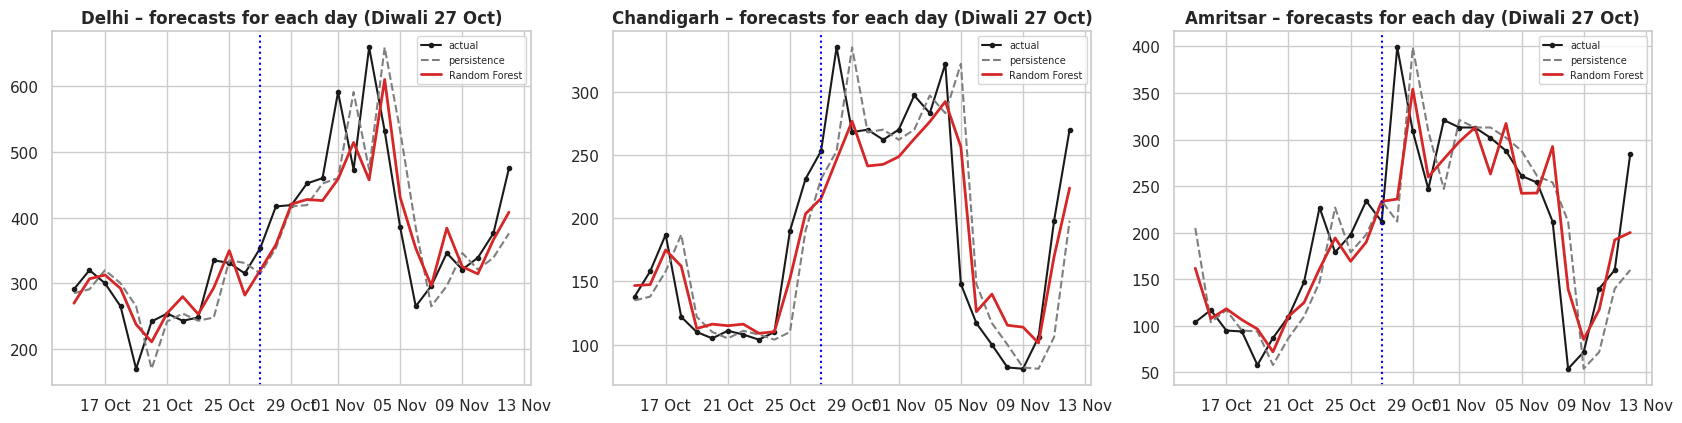

Days whose TARGET day is in the Diwali window, north India (n = 30): MAE model 37.7 vs persistence 53.5
  Gradient Boosting without calendar flags: Diwali-window MAE = 43.3
  Gradient Boosting WITH tomorrow's flags: Diwali-window MAE = 40.5


In [15]:
# Diwali 2019 case study
d0 = pd.Timestamp("2019-10-27")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), sharey=False)
for ax, c in zip(axes, ["Delhi", "Chandigarh", "Amritsar"]):
    g = tp[(tp.city == c) & (tp.date + pd.Timedelta(days=1)).between("2019-10-15", "2019-11-12")].copy(); g["target_date"] = g.date + pd.Timedelta(days=1)
    ax.plot(g.target_date, g.aqi_next, "k-o", ms=3, label="actual"); ax.plot(g.target_date, g.aqi, "--", color="#7f7f7f", label="persistence"); ax.plot(g.target_date, g.pred, "-", color="#d62728", lw=2, label=best_name)
    ax.axvline(d0, color="blue", ls=":"); ax.set_title(f"{c} – forecasts for each day (Diwali 27 Oct)"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); ax.legend(fontsize=7)
plt.tight_layout(); save_fig("07_nextday_diwali_case"); plt.show()
sub = tp[(tp.tm_is_diwali_window == 1) & tp.city.isin(config.NORTH_CITIES)]
print(f"Days whose TARGET day is in the Diwali window, north India (n = {len(sub)}): MAE model {sub.abs_err.mean():.1f} vs persistence {sub.abs_err_persist.mean():.1f}")
# same model WITHOUT tomorrow's calendar flags
p_nocal, _ = fit_nd(G_AR + G_POLL + ["city"], "Gradient Boosting"); p_cal, _ = fit_nd(ALL_ND, "Gradient Boosting")
for nm, p, f in [("Gradient Boosting without calendar flags", p_nocal, G_AR + G_POLL + ["city"]), ("Gradient Boosting WITH tomorrow's flags", p_cal, ALL_ND)]:
    nn, cc = split_nd(f); print(f"  {nm}: Diwali-window MAE = {(p.predict(sub[nn + cc]) - sub.aqi_next).abs().mean():.1f}")

### B3.2 What does the forecast model rely on? (permutation importance on the test set)

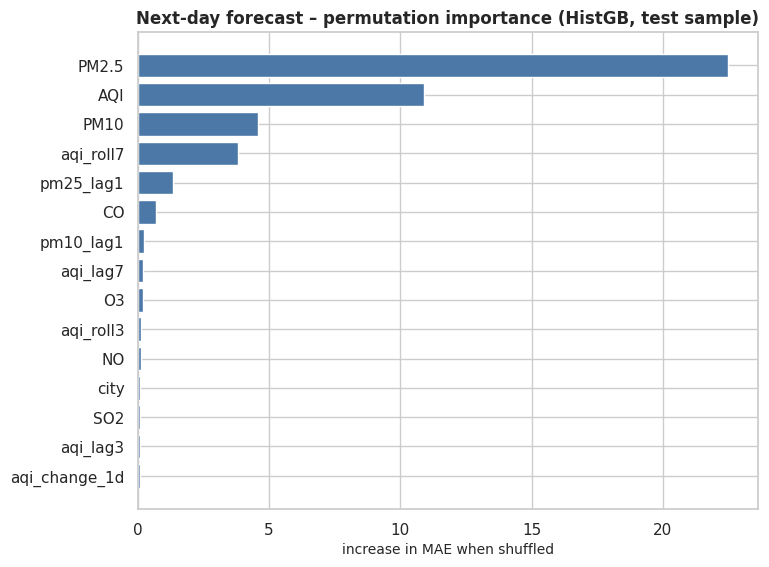

,pm25,aqi,pm10,aqi_roll7,pm25_lag1,co,pm10_lag1,aqi_lag7,o3,aqi_roll3,no_,city,so2,aqi_lag3,aqi_change_1d
ΔMAE,22.48,10.91,4.57,3.81,1.33,0.69,0.25,0.22,0.19,0.11,0.11,0.1,0.1,0.09,0.08


In [16]:
hgb = fitted["Gradient Boosting (HistGB)"]
sample = test_nd.sample(4000, random_state=0)
pi = permutation_importance(hgb, sample[ALL_ND], sample["aqi_next"], scoring="neg_mean_absolute_error", n_repeats=3, random_state=0)
imp = pd.Series(pi.importances_mean, index=ALL_ND).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 6.2)); top = imp.head(15); ax.barh([LABELS.get(i, i) for i in top.index[::-1]], top.values[::-1], color="#4c78a8"); ax.set_xlabel("increase in MAE when shuffled"); ax.set_title("Next-day forecast – permutation importance (HistGB, test sample)")
save_fig("07_nextday_importance"); plt.show(); imp.round(2).head(15).to_frame("ΔMAE").T

## B4 · Next-day category (classification)

In [17]:
cat_cl = modeling.classification_catalog(); cat_cl.pop("Neural Net (MLP)", None)
fitted_c, info_c = {}, {}
for name, spec in cat_cl.items():
    pipe, i = modeling.fit_model(name, spec, num_nd, cat_nd, train_nd[ALL_ND], train_nd["bucket_next"], scoring="f1_macro", n_iter=4)
    if not np.isfinite(i["cv_score"]): i["cv_score"] = cross_val_score(clone(pipe), train_nd[ALL_ND], train_nd["bucket_next"], cv=TimeSeriesSplit(3), scoring="f1_macro").mean()
    fitted_c[name], info_c[name] = pipe, i
cres = {"Persistence (tomorrow = today's category)": {l: evaluate.classification_metrics(d.bucket_next, d.aqi_bucket) for l, d in sets_nd()}}
for n, p in fitted_c.items(): cres[n] = {l: evaluate.classification_metrics(d.bucket_next, p.predict(d[ALL_ND])) for l, d in sets_nd()}
for n, r in cres.items():
    for es, m in r.items(): log_rows += evaluate.to_rows(n + " [classification]", "all", es, m)
cl_tab = pd.DataFrame({n: {"CV macro-F1 (train)": info_c[n]["cv_score"] if n in info_c else np.nan, "test accuracy": r["test"]["accuracy"], "test balanced acc.": r["test"]["balanced_accuracy"],
                           "test precision (macro)": r["test"]["precision_macro"], "test recall (macro)": r["test"]["recall_macro"], "test F1 (macro)": r["test"]["f1_macro"], "within ±1 class": r["test"]["within_1_class"]} for n, r in cres.items()}).T
cl_tab = cl_tab.sort_values("test F1 (macro)", ascending=False).round(3); cl_tab

  Majority class (dummy)       fitted in    0.0s   best params: -
  Logistic Regression          fitted in    0.7s   best params: -
  Decision Tree                fitted in    2.5s   best params: {'min_samples_leaf': 20, 'max_depth': 14}
  Random Forest                fitted in   41.9s   best params: {'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': 12}
  Gradient Boosting (HistGB)   fitted in   45.4s   best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 15, 'learning_rate': 0.1, 'l2_regularization': 1.0}


,CV macro-F1 (train),test accuracy,test balanced acc.,test precision (macro),test recall (macro),test F1 (macro),within ±1 class
Random Forest,0.678,0.774,0.758,0.736,0.758,0.746,0.996
Gradient Boosting (HistGB),0.650,0.760,0.768,0.706,0.768,0.729,0.996
Persistence (tomorrow = today's category),NaN,0.737,0.678,0.674,0.678,0.676,0.992
Logistic Regression,0.573,0.701,0.720,0.632,0.720,0.661,0.991
Decision Tree,0.583,0.675,0.707,0.592,0.707,0.624,0.984
Majority class (dummy),0.087,0.353,0.167,0.059,0.167,0.087,0.853


best next-day classifier by CV: Random Forest


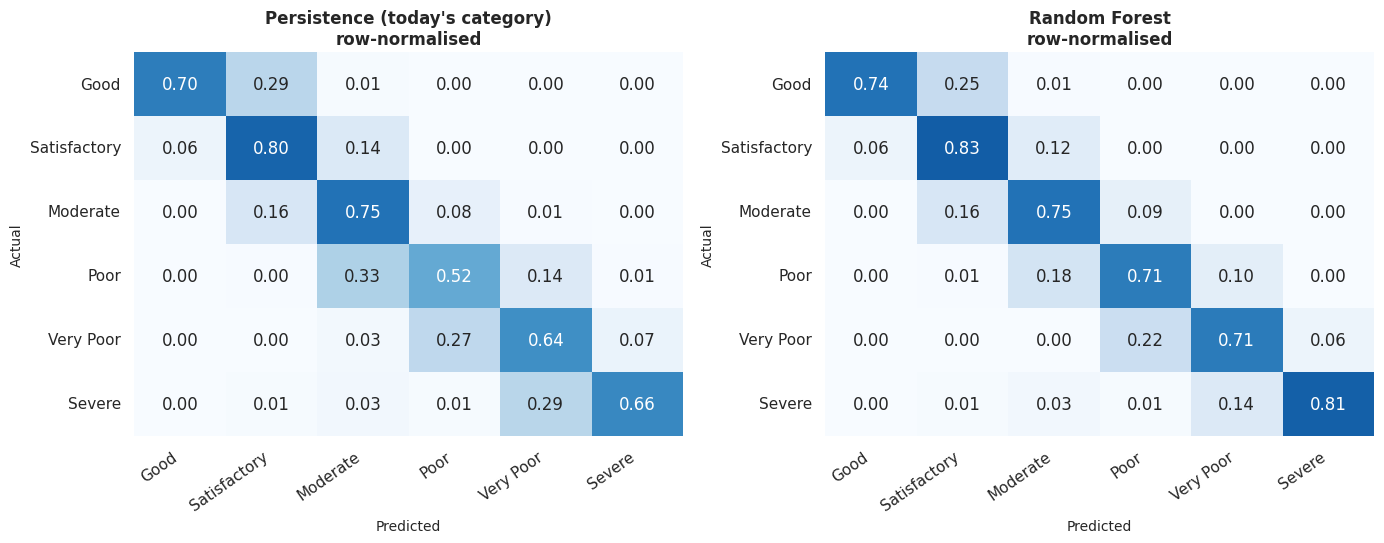

              precision  recall  f1-score    support
Good              0.726   0.745     0.735    924.000
Satisfactory      0.811   0.825     0.818   4427.000
Moderate          0.802   0.746     0.773   3800.000
Poor              0.597   0.708     0.648    969.000
Very Poor         0.751   0.712     0.731    535.000
Severe            0.727   0.815     0.768    124.000
accuracy          0.774   0.774     0.774      0.774
macro avg         0.736   0.758     0.746  10779.000
weighted avg      0.778   0.774     0.775  10779.000


In [18]:
best_c = max((n for n in info_c if n != "Majority class (dummy)"), key=lambda n: info_c[n]["cv_score"]); bc = fitted_c[best_c]
print("best next-day classifier by CV:", best_c)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
evaluate.plot_confusion(test_nd.bucket_next, test_nd.aqi_bucket, "Persistence (today's category)\nrow-normalised", ax=axes[0])
evaluate.plot_confusion(test_nd.bucket_next, bc.predict(test_nd[ALL_ND]), f"{best_c}\nrow-normalised", ax=axes[1])
plt.tight_layout(); save_fig("07_nextday_confusion"); plt.show()
print(pd.DataFrame(classification_report(test_nd.bucket_next, bc.predict(test_nd[ALL_ND]), labels=BUCKET_ORDER, output_dict=True, zero_division=0)).T.round(3).to_string())

## B5 · City scorecard – everything in one table

In [19]:
reg_pred = pd.read_csv(config.RESULTS_DIR / "regression_same_day_predictions.csv", parse_dates=["date"])
same = reg_pred.assign(err=lambda d: (d["Random Forest"] - d["aqi"]).abs()).groupby("city")["err"].mean()
clf_city = pd.read_csv(config.RESULTS_DIR / "classification_by_city.csv").set_index("city")["accuracy"]
sc = tab[["mean_aqi", "pct_poor_or_worse", "main_driver"]].copy()
sc["same-day MAE (RF)"] = same.reindex(sc.index); sc["same-day class accuracy"] = clf_city.reindex(sc.index)
sc["next-day MAE (model)"] = city_nd["MAE_model"].reindex(sc.index); sc["next-day MAE (persistence)"] = city_nd["MAE_persistence"].reindex(sc.index); sc["next-day skill"] = city_nd["skill"].reindex(sc.index)
sc["Diwali 2019 %"] = ev["Diwali % change"]; sc["lockdown vs 2019 %"] = ev["lockdown vs 2019 %"]
sc = sc.loc[CMP].round(2); sc

,mean_aqi,pct_poor_or_worse,main_driver,same-day MAE (RF),same-day class accuracy,next-day MAE (model),next-day MAE (persistence),next-day skill,Diwali 2019 %,lockdown vs 2019 %
city,,,,,,,,,,
Delhi,216.3,44.7,PM10,19.69,0.77,27.71,35.51,0.22,59.1,-44.4
Chandigarh,96.5,7.7,PM10,13.45,0.83,14.52,19.40,0.25,124.3,NaN
Mumbai,109.6,8.2,PM10,11.36,0.67,11.08,13.35,0.17,-2.6,-27.0
Amritsar,112.5,10.2,PM10,16.27,0.75,20.57,24.89,0.17,139.8,-39.9
Gurugram,186.0,31.9,PM2.5,22.38,0.74,26.68,34.66,0.23,46.0,-41.9
Lucknow,185.1,38.8,PM2.5,20.42,0.79,24.83,33.30,0.25,10.9,-45.3
Jaipur,114.0,3.0,PM10,12.83,0.85,14.24,18.54,0.23,71.7,-32.9
Bengaluru,81.1,0.0,PM10,7.62,0.84,7.74,8.94,0.13,11.7,-39.3


## B6 · Save results

In [20]:
tab.to_csv(config.RESULTS_DIR / "city_comparison_table.csv"); ev.to_csv(config.RESULTS_DIR / "city_events.csv"); lp.to_csv(config.RESULTS_DIR / "city_local_vs_pooled.csv", index=False)
abl.to_csv(config.RESULTS_DIR / "nextday_ablation.csv", index=False); nd_tab.to_csv(config.RESULTS_DIR / "nextday_regression_results.csv"); cl_tab.to_csv(config.RESULTS_DIR / "nextday_classification_results.csv")
city_nd.to_csv(config.RESULTS_DIR / "nextday_skill_by_city.csv"); sc.to_csv(config.RESULTS_DIR / "city_scorecard.csv"); corr.to_csv(config.RESULTS_DIR / "city_aqi_correlation.csv"); xc.to_csv(config.RESULTS_DIR / "city_lead_lag.csv")
db.log_results(log_rows, "next_day", conn); conn.close()
joblib.dump(best, config.MODELS_DIR / "nextday_regression_best.joblib", compress=3); joblib.dump(bc, config.MODELS_DIR / "nextday_classifier_best.joblib", compress=3)
for f in ["nextday_regression_best.joblib", "nextday_classifier_best.joblib"]: print(f, f"{(config.MODELS_DIR / f).stat().st_size / 1e6:.2f} MB")

nextday_regression_best.joblib 7.52 MB
nextday_classifier_best.joblib 4.32 MB


## 8 · Conclusions

### Part A – City comparison (like-for-like window, 2 Sep 2019 – 1 Jul 2020)
1. **Delhi is in a league of its own:** mean AQI **216** with **45 %** of days "Poor" or worse, followed by Gurugram (186, 32 %) and Lucknow (185, 39 %). **Chandigarh averages 96.5 with only 7.7 % bad days** – 2.2× cleaner than Delhi and on a par with Mumbai (110, 8 %), cleaner than Amritsar (112) and Jaipur (114). Bengaluru is the cleanest (81, 0 % bad days).
2. **Why Delhi is worse:** PM2.5 106 vs 41 µg/m³ in Chandigarh (2.6×), NO2 39 vs 12 (3.3×). In Chandigarh, Amritsar, Jaipur and Mumbai the AQI is mostly set by **PM10** (coarse dust); in Gurugram and Lucknow by **PM2.5**.
3. **The northern cities breathe together:** daily AQI correlation Delhi–Gurugram **0.96**, Delhi–Lucknow 0.86, Delhi–Chandigarh **0.79**, Chandigarh–Amritsar 0.73, but Chandigarh–Mumbai only 0.30 and Chandigarh–Bengaluru 0.15. The correlation peaks at **lag 0** – episodes are synchronous (shared weather and airshed), with no usable multi-day lead of one city over another (Amritsar's tiny lead on Delhi, 0.54 vs 0.53, is too small to interpret).
4. **Diwali 2019** raised AQI in the north far more than in the south/west: Amritsar **+140 %**, Chandigarh **+124 %** (121 → 271, from "Moderate" to "Poor"), Jaipur +72 %, Delhi +59 %, Gurugram +46 %; Lucknow +11 %, Bengaluru +12 %, Mumbai −3 %. Relative jumps are biggest where the pre-festival baseline is low (Delhi was already at 246).
5. **Lockdown (vs the same dates of 2019):** Lucknow −45 %, Delhi −44 %, Gurugram −42 %, Amritsar −40 %, Bengaluru −39 %, Jaipur −33 %, Mumbai −27 %. Chandigarh has no 2019 comparison; against the weeks just before the lockdown it fell 32 % (mixed with the normal winter→summer decline).
6. **Local vs pooled models:** a model trained on all cities beats city-specific models for Chandigarh (MAE 9.1 vs 14.5), Delhi (14.1 vs 24.0), Amritsar (14.2 vs 18.1) and Gurugram (14.2 vs 15.9); Mumbai is a tie (8.5 vs 8.3). **A model that never saw Chandigarh (zero-shot) is as good as one that did (8.95 vs 9.12)** – the pollutant → AQI mapping is universal, and ~150 days of local data cannot compete with 20 000 days from other cities. Local models also suffer when the regime shifts (lockdown).

### Part B – Predicting tomorrow
7. **"Tomorrow = today" is a strong baseline** (R² 0.80, MAE 21.3): AQI changes slowly, so most of the signal is persistence.
8. **The best models beat it clearly:** Random Forest MAE **17.1** (−19.5 %, R² 0.887) and Gradient Boosting 17.3 (−18.7 %, R² 0.889), against Linear Regression 18.9 (−11 %) and Decision Tree 19.3 (−9 %). The **Neural Net (21.7) does not beat persistence** here – with ~12 000 training rows and ~40 inputs it is outperformed by tree ensembles.
9. **What information matters?** AQI history alone cannot beat persistence (MAE 21.5–22.4). The big gain comes from **today's pollutant readings** (MAE → 17.2–18.5, i.e. −13 to −19 %) – because the AQI is a *maximum*, it throws away information that the individual PM2.5 / PM10 / CO values retain. **Tomorrow's calendar and festival flags add very little overall** (HistGB MAE 17.64 → 17.52) but help on the days they are meant for: on Diwali-window days in north India the error is 40.5 with the flags vs 43.3 without, vs 53.5 for persistence (small sample, n = 30).
10. **Regime matters:** before the lockdown, forecast MAE 18.7 vs 23.8 for persistence; during the lockdown both are ≈ 11.3–11.7 – when pollution is low and stable, persistence is almost unbeatable.
11. **By city:** the error reduction vs persistence ranges from 13 % (Bengaluru) to ≈ 25 % (Chandigarh 14.5 vs 19.4, Lucknow 24.8 vs 33.3); Delhi 27.7 vs 35.5 (−22 %), Mumbai 11.1 vs 13.4 (−17 %).
12. **Next-day category:** Random Forest accuracy **77.4 %**, macro-F1 **0.746** vs persistence 73.7 % / 0.676; 99.6 % of forecasts are within one category. The weaker models (Logistic Regression 0.661, Decision Tree 0.624) fall *below* persistence in macro-F1, so a well-tuned ensemble is needed to add value.
13. **What drives the forecast:** PM2.5 (shuffling it raises MAE by 22), today's AQI (11), PM10 (4.6) and the 7-day mean AQI (3.8).

### Limitations
* One-step-ahead only, evaluated on Jan 2019 – Jun 2020 (including an unusual lockdown regime). Weather (wind, rain, temperature, boundary layer) is not in the data and would be the most valuable addition for forecasting.
* Chandigarh has ~10 months of data; its results are indicative. Mumbai's AQI is 61 % missing.
* Festival effects rest on a handful of Diwali observations per city; dates should be double-checked against an official calendar.
* The dataset's AQI is itself computed from pollutant data, so same-day prediction is partly circular (see notebooks 02 and 05).

### Ideas for future work
Add meteorological features (e.g. from ERA5 / Open-Meteo), multi-day horizons (t+2, t+3), sequence models (LSTM / temporal CNN), station-level data, uncertainty intervals (quantile regression), and a small dashboard for live predictions.